In [1]:
import pandas as pd

df = pd.read_csv("data/Telco-Customer-Churn.csv")
df.shape

FileNotFoundError: [Errno 2] No such file or directory: 'data/Telco-Customer-Churn.csv'

In [3]:
import os
print(os.getcwd())
print(os.listdir())

C:\Users\achal\projects for data science from claude
['.ipynb_checkpoints', '01_data_overview.ipynb', 'Telco-Customer-Churn.csv']


In [5]:
import pandas as pd

df = pd.read_csv("Telco-Customer-Churn.csv")
df.shape

(7043, 21)

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [9]:
df["Churn"].value_counts(normalize=True)

Churn
No     0.73463
Yes    0.26537
Name: proportion, dtype: float64

In [11]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df["TotalCharges"].isna().sum()

11

In [13]:
df[df["TotalCharges"].isna()][["tenure", "MonthlyCharges", "TotalCharges"]]

,tenure,MonthlyCharges,TotalCharges
488,0,52.55,NaN
753,0,20.25,NaN
936,0,80.85,NaN
1082,0,25.75,NaN
1340,0,56.05,NaN
3331,0,19.85,NaN
3826,0,25.35,NaN
4380,0,20.00,NaN
5218,0,19.70,NaN
6670,0,73.35,NaN


In [15]:
df["TotalCharges"] = df["TotalCharges"].fillna(0)
df["TotalCharges"].isna().sum()

0

In [17]:
pd.crosstab(df["Contract"], df["Churn"], normalize="index")

Churn,No,Yes
Contract,,
Month-to-month,0.572903,0.427097
One year,0.887305,0.112695
Two year,0.971681,0.028319


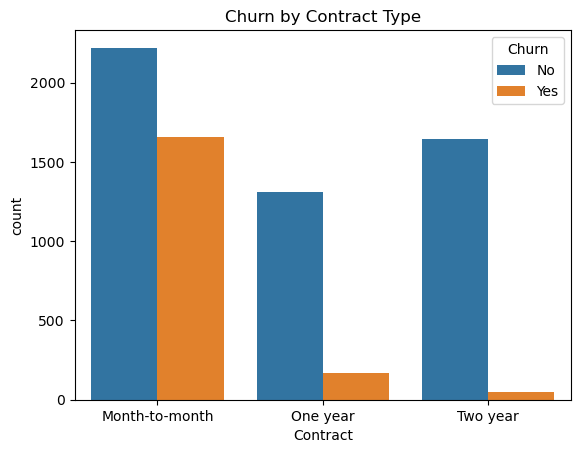

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(data=df, x="Contract", hue="Churn")
plt.title("Churn by Contract Type")
plt.show()

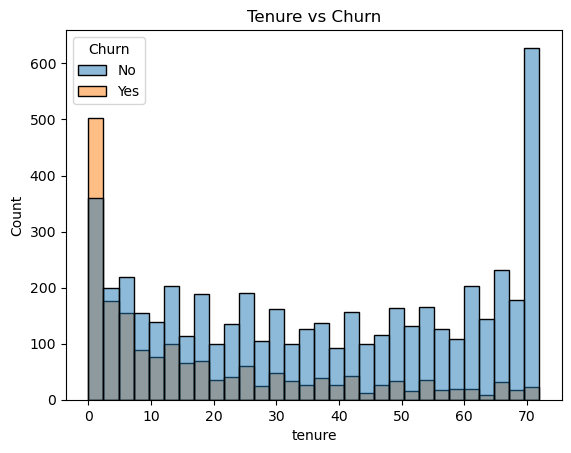

In [21]:
sns.histplot(data=df, x="tenure", hue="Churn", bins=30)
plt.title("Tenure vs Churn")
plt.show()

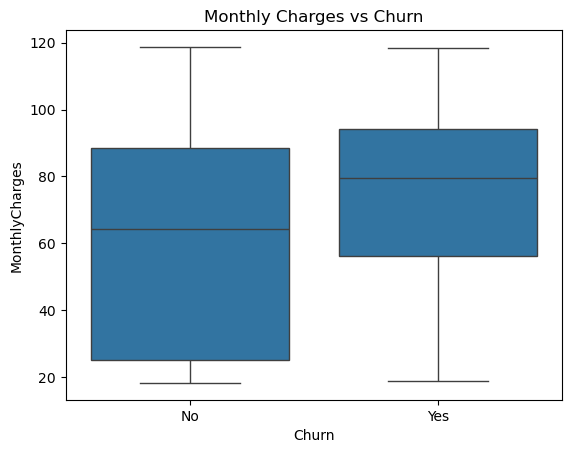

In [23]:
sns.boxplot(data=df, x="Churn", y="MonthlyCharges")
plt.title("Monthly Charges vs Churn")
plt.show()

In [25]:
pd.crosstab(df["InternetService"], df["Churn"], normalize="index")

Churn,No,Yes
InternetService,,
DSL,0.810409,0.189591
Fiber optic,0.581072,0.418928
No,0.925950,0.074050


In [27]:
df = df.drop("customerID", axis=1)
df["Churn"] = df["Churn"].map({"Yes": 1, "No": 0})
df["Churn"].value_counts()

Churn
0    5174
1    1869
Name: count, dtype: int64

In [29]:
df_encoded = pd.get_dummies(df, drop_first=True)
df_encoded.shape

(7043, 31)

In [33]:
X = df_encoded.drop("Churn", axis=1)
y = df_encoded["Churn"]

In [35]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
X_train.shape, X_test.shape

((5634, 30), (1409, 30))

In [37]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)
model.score(X_test, y_test)

C:\Users\achal\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


0.8048261178140526

In [39]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

model = LogisticRegression(max_iter=1000)
model.fit(X_train_scaled, y_train)
model.score(X_test_scaled, y_test)

0.8069552874378992

In [41]:
from sklearn.metrics import classification_report

y_pred = model.predict(X_test_scaled)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1035
           1       0.66      0.57      0.61       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



In [43]:
model_bal = LogisticRegression(max_iter=1000, class_weight="balanced")
model_bal.fit(X_train_scaled, y_train)

y_pred_bal = model_bal.predict(X_test_scaled)
print(classification_report(y_test, y_pred_bal))

              precision    recall  f1-score   support

           0       0.90      0.72      0.80      1035
           1       0.51      0.79      0.62       374

    accuracy                           0.74      1409
   macro avg       0.71      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409



In [45]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=200, class_weight="balanced", random_state=42)
rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)
print(classification_report(y_test, y_pred_rf))

              precision    recall  f1-score   support

           0       0.83      0.89      0.86      1035
           1       0.63      0.50      0.56       374

    accuracy                           0.79      1409
   macro avg       0.73      0.70      0.71      1409
weighted avg       0.78      0.79      0.78      1409



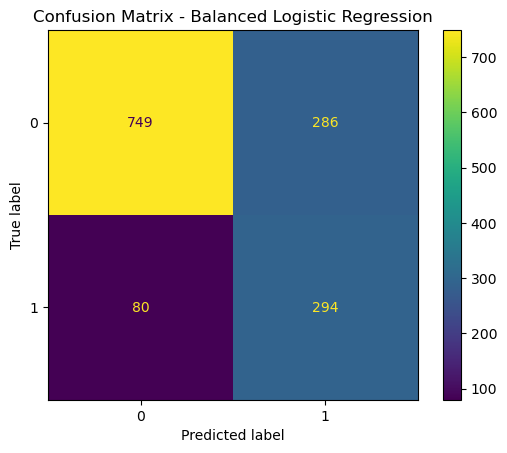

In [47]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_bal)
plt.title("Confusion Matrix - Balanced Logistic Regression")
plt.show()

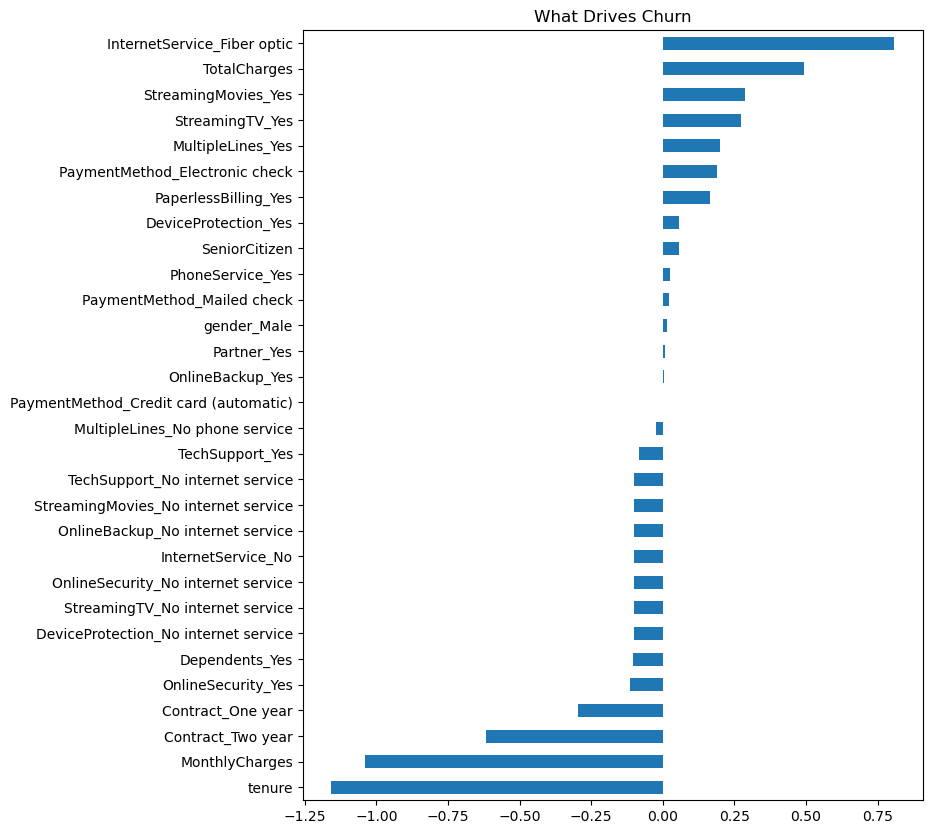

In [49]:
coef = pd.Series(model_bal.coef_[0], index=X.columns).sort_values()
coef.plot(kind="barh", figsize=(8, 10))
plt.title("What Drives Churn")
plt.show()

In [51]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)
X_train_sm, y_train_sm = smote.fit_resample(X_train_scaled, y_train)

print(y_train.value_counts())
print(y_train_sm.value_counts())

C:\Users\achal\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\achal\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Users\achal\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\achal\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Users\achal\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreatePro

Churn
0    4139
1    1495
Name: count, dtype: int64
Churn
0    4139
1    4139
Name: count, dtype: int64


In [53]:
model_sm = LogisticRegression(max_iter=1000)
model_sm.fit(X_train_sm, y_train_sm)

y_pred_sm = model_sm.predict(X_test_scaled)
print(classification_report(y_test, y_pred_sm))

              precision    recall  f1-score   support

           0       0.91      0.72      0.80      1035
           1       0.50      0.80      0.62       374

    accuracy                           0.74      1409
   macro avg       0.71      0.76      0.71      1409
weighted avg       0.80      0.74      0.75      1409



In [58]:
from xgboost import XGBClassifier

ratio = (y_train == 0).sum() / (y_train == 1).sum()

xgb = XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4,
                    scale_pos_weight=ratio, random_state=42)
xgb.fit(X_train, y_train)

y_pred_xgb = xgb.predict(X_test)
print(classification_report(y_test, y_pred_xgb))

              precision    recall  f1-score   support

           0       0.91      0.74      0.81      1035
           1       0.52      0.79      0.63       374

    accuracy                           0.75      1409
   macro avg       0.71      0.76      0.72      1409
weighted avg       0.80      0.75      0.76      1409



In [57]:
%pip install xgboost

   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.5/48.9 MB 15.9 MB/s eta 0:00:04
   ---------------------------------------- 0.6/48.9 MB 7.6 MB/s eta 0:00:07
    --------------------------------------- 0.7/48.9 MB 5.7 MB/s eta 0:00:09
    --------------------------------------- 0.8/48.9 MB 4.6 MB/s eta 0:00:11
    --------------------------------------- 0.9/48.9 MB 4.0 MB/s eta 0:00:13
    --------------------------------------- 1.0/48.9 MB 3.9 MB/s eta 0:00:13
    --------------------------------------- 1.1/48.9 MB 3.7 MB/s eta 0:00:13
    --------------------------------------- 1.2/48.9 MB 3.3 MB/s eta 0:00:15
   - -------------------------------------- 1.3/48.9 MB 3.1 MB/s eta 0:00:16
   - -------------------------------------- 1.4/48.9 MB 3.2 MB/s eta 0:00:15
   - -------------------------------------- 1.4/48.9 MB 3.2 MB/s eta 0:00:15
   - -------------------------------------- 1.4/48.9 MB 3.2 MB/s eta 0:00:15
   - 

In [61]:
from sklearn.metrics import roc_auc_score

print("Logistic balanced:", roc_auc_score(y_test, model_bal.predict_proba(X_test_scaled)[:, 1]))
print("Logistic SMOTE:   ", roc_auc_score(y_test, model_sm.predict_proba(X_test_scaled)[:, 1]))
print("Random Forest:    ", roc_auc_score(y_test, rf.predict_proba(X_test)[:, 1]))
print("XGBoost:          ", roc_auc_score(y_test, xgb.predict_proba(X_test)[:, 1]))

Logistic balanced: 0.8414012245214291
Logistic SMOTE:    0.8405073755457387
Random Forest:     0.8245718050065877
XGBoost:           0.838821721046785


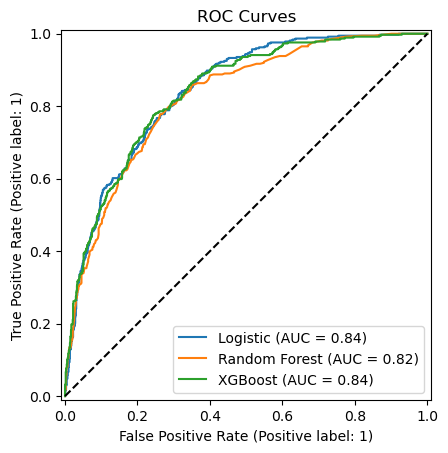

In [63]:
from sklearn.metrics import RocCurveDisplay

ax = plt.gca()
RocCurveDisplay.from_predictions(y_test, model_bal.predict_proba(X_test_scaled)[:, 1], name="Logistic", ax=ax)
RocCurveDisplay.from_predictions(y_test, rf.predict_proba(X_test)[:, 1], name="Random Forest", ax=ax)
RocCurveDisplay.from_predictions(y_test, xgb.predict_proba(X_test)[:, 1], name="XGBoost", ax=ax)
plt.plot([0, 1], [0, 1], "k--")
plt.title("ROC Curves")
plt.show()

In [65]:
from sklearn.model_selection import GridSearchCV

params = {
    "max_depth": [3, 4, 5],
    "learning_rate": [0.01, 0.05, 0.1],
    "n_estimators": [200, 400],
}

grid = GridSearchCV(
    XGBClassifier(scale_pos_weight=ratio, random_state=42),
    params, cv=5, scoring="roc_auc", n_jobs=-1
)
grid.fit(X_train, y_train)

print("Best settings:", grid.best_params_)
print("Best CV AUC:", grid.best_score_)
print("Test AUC:", roc_auc_score(y_test, grid.predict_proba(X_test)[:, 1]))

Best settings: {'learning_rate': 0.01, 'max_depth': 3, 'n_estimators': 400}
Best CV AUC: 0.8470712180640337
Test AUC: 0.8435841793898059


In [67]:
import joblib

joblib.dump(model_bal, "churn_model.pkl")
joblib.dump(scaler, "scaler.pkl")
joblib.dump(list(X.columns), "columns.pkl")

['columns.pkl']

In [69]:
loaded_model = joblib.load("churn_model.pkl")
loaded_scaler = joblib.load("scaler.pkl")

sample = X_test.iloc[[0]]
prob = loaded_model.predict_proba(loaded_scaler.transform(sample))[0, 1]
print(f"Churn probability: {prob:.0%}")

Churn probability: 12%
